# Multimodal Music Analysis

The target of this project is the implementation of a complete pipeline for extracting knowledge from music data by combining two different modalities: **Audio** and **Text**. The project is split into two parts:  
1. Preprocessing of the data, generation of embeddings and researching analysis.
2. Classification, Fusion and Evaluation.  
  
This notebook contains the implementation of part 1.


Requirements:

In [1]:
%pip install seaborn
%pip install datasets
%pip install matplotlib
%pip install vaderSentiment
%pip install kneed
%pip install contractions
%pip install pyspellchecker
%pip install scikit-learn
%pip install pandas
%pip install wordcloud
%pip install tensorflow
%pip install gensim

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## **Introduction**  

Firstly, we focus on preprocessing our data and create one final dataframe to work on. We keep a subset of the total songs with the necessary columns to complete our research.  
- We keep songs that belong to the following genres:  
`"latin", "classical", "metal", "jazz", "rap"`  
having in mind the difference and the fame of these genres.  

- We keep all the songs that belong to multiple genres, so we introduce a new column in our dataframe `main_genre` to express the main genre of each song

- We extract the lyrics of each song after parsing the text files (form of the files: `{song_id}.txt`)

- We collect the MFCC stats for each song and we store them as vectors (1x104) for each song in our dataframe.

After, we extract audio and text embeddings from our MFCC stats in order to reduce the dimensionality of the vectors we will work on later. We follow this steps:  

- Extracting audio embeddings from the MFCC stats using Autoencoder and PCA.

- Extraction text embeddings from the lyrics of the song using the `Word2Vec` model from gensim.

In the last part, we visualise and analyse our researching results.

## 1. Data Collection


In [2]:
import pandas as pd
import os
import re

import numpy as np
import tensorflow as tf
import sklearn

import matplotlib.pyplot as plt

- Run the code in the next sections for pre-processing the data 
- In case the file already exists, the next sections are skipped automatically

In [3]:
def normalize_genre(genre, genres_list):
    if genre is None:
        return None
    
    # lowercase
    genre = genre.lower()

    # remove spaces and hyphens
    genre = re.sub(r"[\\-]+", "", genre)
    
    for g in genres_list:
        if g in genre:
            return g

    return genre

def filter_by_genres(df, genres_list):

    df["genres"] = df['genres'].apply(
            lambda x: list(set(str(x).split(",")))
        )
    df["main_genre"] = df['genres'].apply(
            lambda x: normalize_genre(x[0].strip(), genres_list)
        )

    return df[df["main_genre"].isin(genres_list)]

In [4]:
def create_lyrics_df(target_ids, path='data/processed_lyrics'):
    # --- Filtering the lyrics of the songs ---
    lyrics_folder = path

    lyrics_data = []

    for filename in os.listdir(lyrics_folder):
        if filename.endswith('.txt'):
            song_id = filename.replace('.txt', '')
            
            if song_id in target_ids:
                file_path = os.path.join(lyrics_folder, filename)
                
                with open(file_path, 'r', encoding='utf-8') as f:
                    lyrics_text = f.read()
                
                lyrics_data.append({
                    'id': song_id,
                    'lyrics': lyrics_text
                })

    lyrics_df = pd.DataFrame(lyrics_data)
    return lyrics_df

In [5]:
def merge_dataframes(dfs, merge_on):
    merged_df = dfs[0]

    for df in dfs[1:]:
        merged_df = pd.merge(merged_df, df, on=merge_on)

    return merged_df


In [6]:

def collect_data():
    # --- Importing the datasets ---
    genres_df = pd.read_csv('data/id_genres.csv', sep='\t') 
    information_df = pd.read_csv('data/id_information.csv', sep='\t')
    tags_df = pd.read_csv('data/id_tags.csv', sep='\t')
    mfcc_stats_df = pd.read_csv('data/id_mfcc_stats.tsv', sep='\t').dropna()

    # ---- Group mfcc stats in one column for better data ----
    mfcc_stats_df = mfcc_stats_df.copy()

    mfcc_columns = [col for col in mfcc_stats_df.columns if 'mfcc' in col.lower() or 'cov' in col.lower()]

    mfcc_stats_df['audio_stats'] = mfcc_stats_df[mfcc_columns].values.tolist()

    audio_stats_df = mfcc_stats_df.drop(columns=mfcc_columns)

    # --- Filtering the genres dataset to only include the top n most common genres ---
    genres_list = ["latin", "classical", "metal", "jazz", "rap"]
    filtered_genres_df = filter_by_genres(genres_df, genres_list)

    # --- Create dataframe with the lyrics of the songs ---
    lyrics_df = create_lyrics_df(target_ids=set(filtered_genres_df['id'].astype(str)))

    # --- Merging dataframes ---
    dataframes = [filtered_genres_df, information_df, tags_df, audio_stats_df, lyrics_df]
    df = merge_dataframes(dataframes, "id")

    # --- Handling missing and duplicate values ---
    df = df[df['lyrics'].notna()]
    df = df[df['genres'].notna()]
    df = df[df['genres'].str.strip() != '']
    df = df.drop_duplicates(subset='id', keep='first')

    return df
    

In [7]:
final_df_path = "data/final_data.pkl"
if (os.path.isfile(path=final_df_path)):
    data = pd.read_pickle(final_df_path,)
else:
    data = collect_data()
    data = data.drop(columns=["artist", "album_name"])
    data.to_pickle(final_df_path)
    

data.head()

,id,genres,main_genre,song,tags,audio_stats,lyrics
0,006TYKNjNxWjfKjy,"[symphonic metal, symphonic power metal, power...",metal,Flames of Revenge,"symphonic metal,power metal,symphonic power metal","[23.30799674987793, -8.152815818786621, -17.38...",princess must assist death endur tragic pain c...
1,00i0OB17z3m3yamO,"[alternative metal, alternative rock, rock]",metal,Sign of the Times,"alternative rock,rock,alternative metal,altern...","[24.25779724121093, -10.212427139282228, -4.85...",sign time anoth mountain climb sun burn hot fl...
2,00mLjKFmaTv9MdaB,"[rap, hip hop, pop]",rap,Boom Boom Pow,"dance,hip hop,pop,hip-hop,rap","[20.77475357055664, -6.112589359283447, -10.24...",get get get get get get get get boom boom boom...
3,01ScM29f0wF2Mnkq,"[rap, indie pop, electronic]",rap,Implicit Demand for Proof,"electronic,alternative,rap,indie,indie pop","[21.80247497558593, 2.8943941593170166, -16.29...",know liar know could set fire day go ahead mak...
4,01gyRHLquwXDlhkO,[rap],rap,Somebody's Gotta Die,"rap,hip-hop,gangsta rap,east coast rap","[22.731481552124023, -12.233457565307615, 2.38...",sittin crib dreamin leer jet coup way salt sho...


## 2. Feature Extraction

### **Audio Embeddings**

### Autoencoder
Creating and training a simple Autoencoder to compress the vector of the audio embedding to a vector with fewer dimensions.

In [8]:
class Autoencoder(tf.keras.Model):
    def __init__(self, input_dim, encoding_dim=32):
        super(Autoencoder, self).__init__()

        layers = tf.keras.layers

        self.encoder = tf.keras.Sequential([
            layers.Input(shape=(input_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(encoding_dim, activation='relu')
        ])

        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(encoding_dim,)),
            layers.Dense(64, activation='relu'),
            layers.BatchNormalization(),
            layers.Dropout(0.2),
            layers.Dense(input_dim, activation='linear')
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

In [9]:
from sklearn.preprocessing import StandardScaler
from keras.callbacks import EarlyStopping, TensorBoard
from sklearn.model_selection import train_test_split


'''
Function to train the autoencoder.
Arguments:  - scaled audio_stats from the dataframe ready for training
            - optional: hyperparameters for the training
Returns:    - training history for visualization
            - the trained autoencoder
'''
def autoencoder_training(audio_stats, encoding_dim=32, optimizer="adam", loss="mse",
                         epochs=100, batch_size=32, early_stopping_epoch=20):

    input_dim = audio_stats.shape[1]

    # --- autoencoder ---
    autoencoder = Autoencoder(input_dim, encoding_dim)

    autoencoder.compile(optimizer=optimizer, loss=loss)

    # --- autoencoder training ---
    early_stopping = EarlyStopping(
        monitor='val_loss',
        patience=early_stopping_epoch,
        restore_best_weights=True
    )
    X_train, X_val = train_test_split(audio_stats, test_size=0.2, random_state=42)

    training = autoencoder.fit(
                        X_train, X_train,
                        validation_data=(X_val, X_val),
                        epochs=epochs,
                        batch_size=batch_size,
                        shuffle=True,
                        callbacks=[early_stopping]
                    )

 
    return training, autoencoder    


In [10]:
# --- Extraction the audio embeddings from the audio stats column ---
audio_embeddings = np.array(data["audio_stats"].to_list(), dtype=float)
scaler = StandardScaler()
audio_embed_train = scaler.fit_transform(audio_embeddings)

training, autoencoder = autoencoder_training(audio_stats=audio_embed_train, epochs=200, optimizer="adam", early_stopping_epoch=5)



Epoch 1/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.6862 - val_loss: 0.5793
Epoch 2/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4746 - val_loss: 0.4862
Epoch 3/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4044 - val_loss: 0.4221
Epoch 4/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3652 - val_loss: 0.3963
Epoch 5/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3411 - val_loss: 0.3908
Epoch 6/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3257 - val_loss: 0.3569
Epoch 7/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3123 - val_loss: 0.3556
Epoch 8/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3042 - val_loss: 0.3417
Epoch 9/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2986 - val_loss: 0.3380
Epoch 10/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2912 - val_loss: 0.3379
Epoch 11/200
433/433 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2868 - val_loss: 0.3237
Epoch 12/200
433/433 ━━━━━━━━━━━━━━━━━━━━

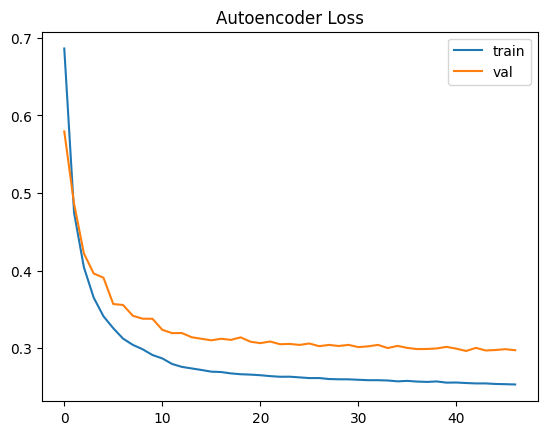

In [11]:
plt.plot(training.history['loss'], label='train')
plt.plot(training.history['val_loss'], label='val')
# plt.ylim(0, 1.0)
plt.legend()
plt.title("Autoencoder Loss")
plt.show()

In [12]:
# --- final compresses audio embeddings with 32 dim ---

autoenc_audio_embeddings = autoencoder.encoder.predict(audio_embed_train)
print(autoenc_audio_embeddings.shape)

541/541 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
(17299, 32)


### Principal Component Analysis (PCA)

In [13]:
from sklearn.decomposition import PCA

audio_embeddings = np.array(data["audio_stats"].tolist(), dtype=float)
scaler = StandardScaler()
audio_scaled = scaler.fit_transform(audio_embeddings)


pca = PCA(n_components=0.95)  # keep 95% variance
pca_audio_embeddings = pca.fit_transform(audio_scaled)

pca_audio_embeddings.shape

(17299, 77)

In the next section, we compare the difference between PCA and Autoencoder audio embeddings, as well as the text embeddings to the audio embeddings.   

### **Text Embeddings**

In [14]:
import re
import numpy as np
from gensim.models import Word2Vec

#Προεπεξεργασία Lyrics

def preprocess_lyrics(text):
    if not isinstance(text, str):
        return []
    #Αφαίρεση περιεχομένου σε αγκύλες π.χ. [Chorus]
    text = re.sub(r'\[.*?\]', '', text)
    #Μετατροπή σε πεζά (για να αναγνωρίζουμε ίδιες λέξεις)
    text = text.lower()
    #Κρατάμε μόνο γράμματα και αποστροφές, όλα τα άλλα τα πετάμε πχ. αριθμούς
    text = re.sub(r"[^a-z\s']", '', text)
    #Βγάζουμε τα tokens τώρα αλλά όχι τις λέξεις με 2 ή λιγότερα γράμματα (είναι άχρηστες)
    tokens = [t for t in text.split() if len(t) >= 2]
    return tokens

#Εφαρμογή
print("Προεπεξεργασία lyrics...")
data['lyrics_tokens'] = data['lyrics'].apply(preprocess_lyrics)

#Παράδειγμα για να ελέγξουμε ότι το κάναμε σωστά
print(f"Παράδειγμα tokens:\n{data['lyrics_tokens'].iloc[32][:15]}")
print(f"Σύνολο τραγουδιών: {len(data)}")

Προεπεξεργασία lyrics...
Παράδειγμα tokens:
['awok', 'impact', 'surveil', 'camera', 'eye', 'search', 'high', 'low', 'crimin', 'mind', 'find', 'scene', 'crime', 'handcuff', 'blind']
Σύνολο τραγουδιών: 17299


In [15]:
#Εκπαίδευση Word2Vec

#Το corpus θα είναι η λίστα με τα tokenized lyrics που προέκυψε παραπάνω,
#την οποία μετατρέπουμε σε απλή python λίστα για να αναγνωρίζεται από το μον΄τελο.
corpus = data['lyrics_tokens'].tolist()

print("Εκπαίδευση Word2Vec μοντέλου...")
w2v_model = Word2Vec(
    sentences=corpus,
    vector_size=100,   #Διάσταση embedding
    window=5,          #Πλαίσιο γειτονικών λέξεων (κοιτάζει τις 2 αριστερές και 2 δεξιές λέξεις)
    min_count=3,       #Αγνόησε λέξεις που εμφανίζονται < 3 φορές (δεν βοηθάνε να βγάλουμε συμπεράσματα)
    workers=4,         #Παράλληλη εκπαίδευση (4 CPUs)
    epochs=10,         #Θα διαβάσει το corpus 10 φορές
    sg=1               #Θα προσπαθεί μέσω μιας λέξης να προβλέπει τις γύρω λέξεις (skip gram algorithm)
)

print(f"Συνολική ποσότητα λέξεων: {len(w2v_model.wv)}")
print(f"Παράδειγμα - λέξεις κοντά στο 'say': {w2v_model.wv.most_similar('say', topn=5)}")

#Αποθήκευση 
w2v_model.save("data/word2vec_lyrics.model")
print("Μοντέλο αποθηκεύτηκε!")

Εκπαίδευση Word2Vec μοντέλου...
Συνολική ποσότητα λέξεων: 19469
Παράδειγμα - λέξεις κοντά στο 'say': [('exclam', 0.7365590333938599), ('alaina', 0.7106983661651611), ('huey', 0.702645480632782), ('naiveti', 0.6982545256614685), ('plebeian', 0.698046088218689)]
Μοντέλο αποθηκεύτηκε!


In [16]:

#Δημιουργία Song Embeddings 

#Η παρακάτω συνάρτηση επεξεργάζεται 1 τραγούδι κάθε φορά, παίρνει κάθε λέξη που έχουμε βάλει από πριν στα tokens του τραγουδιού αυτού
#και τοποθετεί το διάνυσμά της (100 αριθμοί) στον πίνακα vectors. 'Υστερα υπολογίζει το μέσο όρο ανά στήλη των διανυσμάτων του πίνακα και
#δημιουργεί το song embedding.

def get_song_embedding(tokens, model, vector_size=100):
  
    vectors = []
    
    for token in tokens: #Για κάθε λέξη που ανήκει στο word2vec model μας, βάλε το διάνυσμά της στον πίνακα vectors
        if token in model.wv:
            vectors.append(model.wv[token])
    
    if len(vectors) == 0:
        #Έλεγχος σφάλματος
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0) #Επέστρεψε το μέσο όρο αν΄ά στήλη όλων των λέξεων-διανυσμάτων του τραγουδιού που είναι το song embedding.

print("Δημιουργία song embeddings...")
data['text_embedding'] = data['lyrics_tokens'].apply(
    lambda tokens: get_song_embedding(tokens, w2v_model, vector_size=100) #Lambda για να περάσουμε και τα 3 ορίσματα μαζί
)

#Αποθηκεύουμε τα embeddings σε ξεχωριστό αρχείο, με μορφή 2D πίνακα
text_embeddings_matrix = np.vstack(data['text_embedding'].values)
np.save("data/text_embeddings.npy", text_embeddings_matrix)

print(f"Shape των text embeddings: {text_embeddings_matrix.shape}")
#Αναμενόμενο: (αριθμός τραγουδιών, 100)
print("Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy")

Δημιουργία song embeddings...
Shape των text embeddings: (17299, 100)
Text embeddings αποθηκεύτηκαν στο data/text_embeddings.npy


In [17]:
text_embeddings_matrix[0]

array([ 0.25572634,  0.10830931, -0.15926382, -0.08492228,  0.04269619,
       -0.24705261,  0.19615529, -0.13577552,  0.21082561,  0.10887957,
       -0.15489741,  0.16337776, -0.24372979,  0.10216374, -0.107447  ,
       -0.05768272,  0.07126024,  0.16409467, -0.25527334, -0.38425115,
        0.21569631,  0.40893069, -0.05346195,  0.1516124 , -0.29434121,
       -0.06159204, -0.07053418, -0.25853109,  0.03172329,  0.28645021,
       -0.00561824,  0.09373146,  0.22702716, -0.29292274,  0.0012598 ,
        0.25749469,  0.09423728, -0.14227912, -0.14918005, -0.33361557,
       -0.0237103 , -0.20960431, -0.08624528, -0.12609793,  0.03018915,
       -0.39514583, -0.26022035,  0.06112099,  0.18187393,  0.37635651,
       -0.22941777, -0.01873256,  0.20363139, -0.22517042,  0.13206169,
        0.21442303, -0.10284838, -0.01780031, -0.05186397,  0.25866246,
        0.07597794,  0.00420089, -0.2065357 , -0.28620589, -0.24064279,
        0.31096265,  0.26564839,  0.03357523, -0.27387676, -0.01

## 3. Visualization and Analysis

### **Wordcloud**
Analyzing in wordclouds the most frequent words used in the tags of **rap** and **rock** songs.

In [18]:
# Preparing the data for word cloud generation
wordcloud_df = data[['main_genre','tags']]
rap_df = wordcloud_df[wordcloud_df['main_genre'] == 'rap']
classical_df = wordcloud_df[wordcloud_df['main_genre'] == 'classical'] 

rap_tags = " ".join(rap_df['tags'].dropna())
classical_tags = " ".join(classical_df['tags'].dropna())

In [19]:
from wordcloud import WordCloud


def create_wordcloud(text, title, color='white'):

    wordcloud = WordCloud(width=800, height=400, background_color=color).generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(title)
    plt.show()

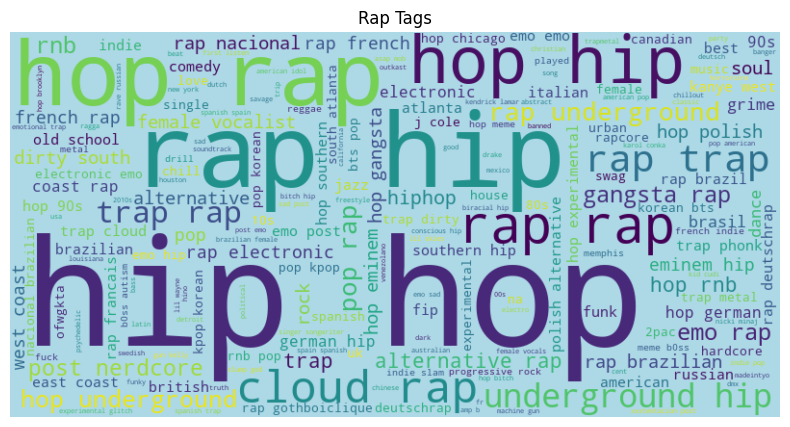

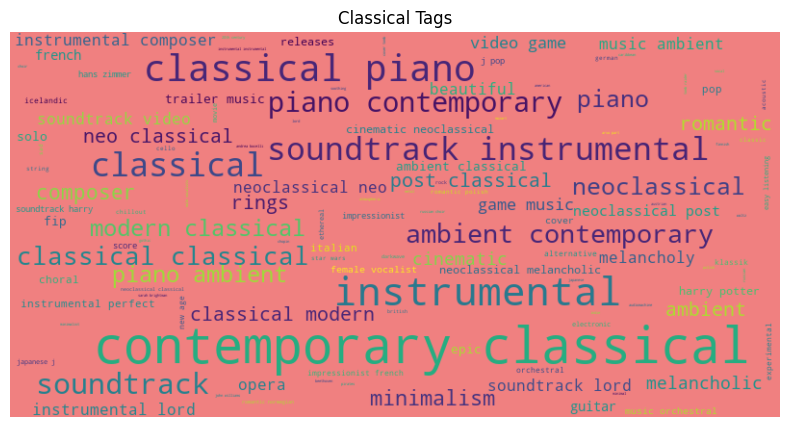

In [20]:
# Creating wordclouds for rap and rock genres
create_wordcloud(rap_tags, 'Rap Tags', color='lightblue')
create_wordcloud(classical_tags, 'Classical Tags', color='lightcoral')


### **Bar Chart**

Present the 10 most appeared tags grouped by the genre of the songs

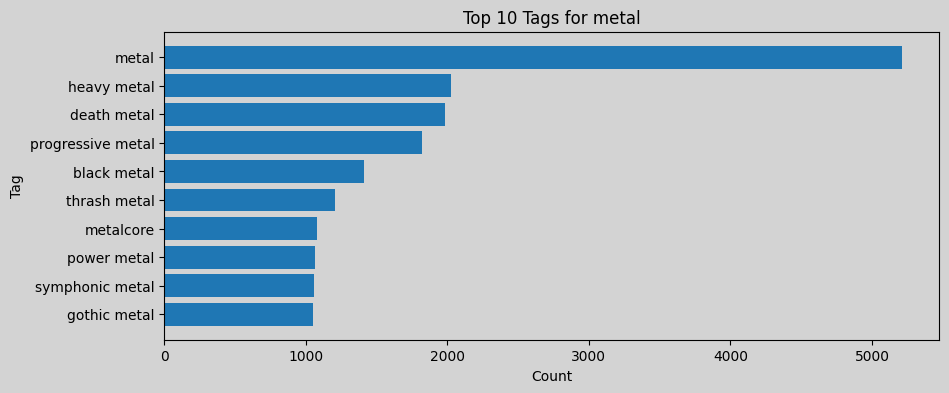

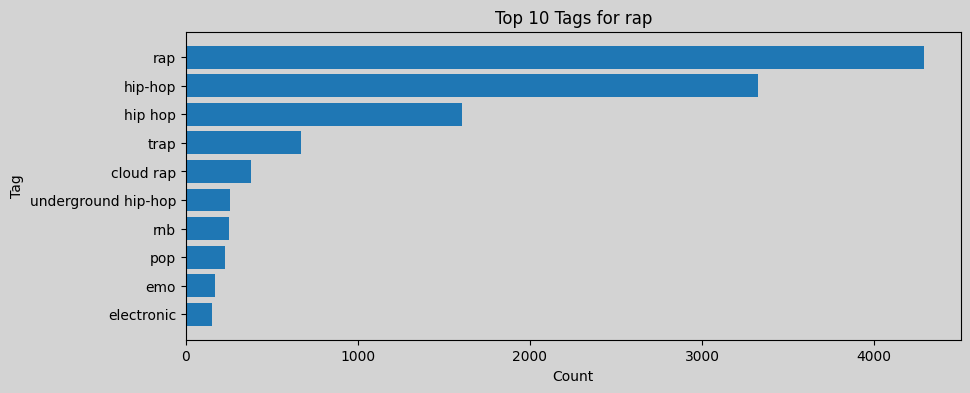

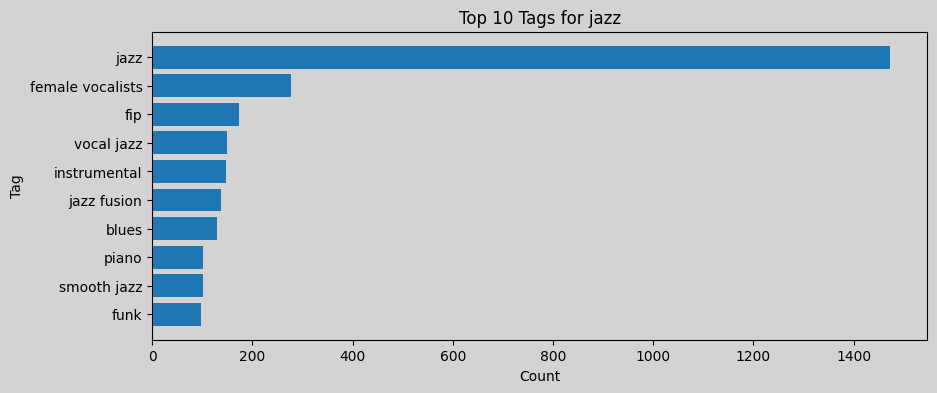

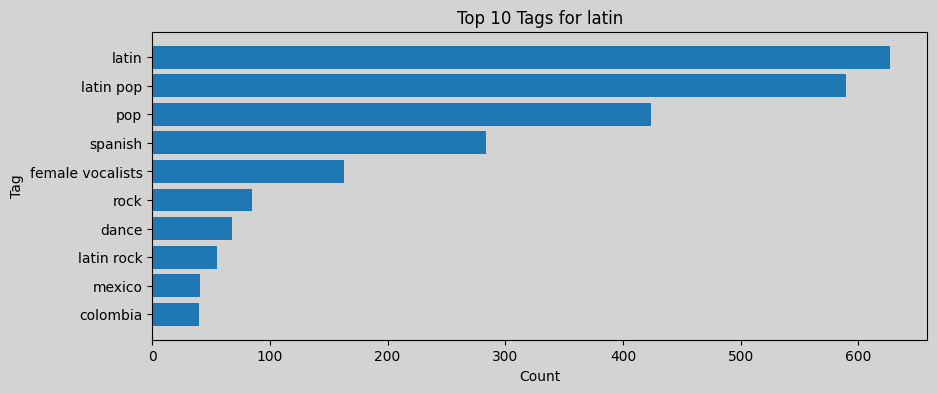

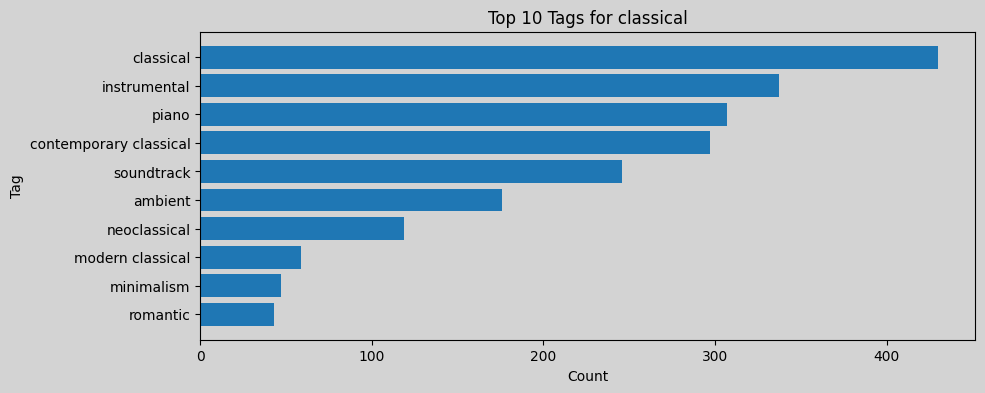

In [21]:
from collections import Counter
import matplotlib.pyplot as plt

data['tags_list'] = data['tags'].fillna('').apply(
    lambda x: [tag.strip() for tag in x.split(',') if tag.strip() != '']
)

for genre in data['main_genre'].unique():
    subset = data[data['main_genre'] == genre]

    all_tags = [tag for tags in subset['tags_list'] for tag in tags]

    tag_counts = Counter(all_tags)
    top_tags = tag_counts.most_common(10)

    tags, counts = zip(*top_tags)

    plt.figure(figsize=(10, 4)).patch.set_facecolor('lightgray')
    plt.barh(tags, counts)
    plt.gca().invert_yaxis()
    plt.gca().set_facecolor('lightgray')
    plt.title(f"Top 10 Tags for {genre}")
    plt.xlabel("Count")
    plt.ylabel("Tag")
    plt.show()

### **Dimensionality Reduction**

**Scatter Plot**  
We introduce the following function to help us compare the scatter plots between embedding generated on different bases.

In [22]:
from sklearn.manifold import TSNE

def scatter_plot_comparison(embed1, embed2, title1="PCA Embeddings", title2="Autoencoder Embeddings", data=data):

    # --- t-SNE visualization of the PCA and autoencoder embeddings ---
    tsne = TSNE(n_components=2, learning_rate=200, perplexity=50, max_iter=2000, random_state=42)
    X1 = tsne.fit_transform(embed1)
    X2 = tsne.fit_transform(embed2)

    # --- color the points by genre ---
    categories = data['main_genre'].astype('category')
    y = categories.cat.codes
    genre_names = categories.cat.categories

    # --- scatter plot of the t-SNE embeddings colored by genre ---
    fig, axes = plt.subplots(1,2, figsize=(12,6))

    scatter1 = axes[0].scatter(X1[:,0], X1[:,1], c=y, cmap='tab10', s=5)
    axes[0].set_title(title1)

    scatter2 = axes[1].scatter(X2[:,0], X2[:,1], c=y, cmap='tab10', s=5)
    axes[1].set_title(title2)

    handles, _ = scatter1.legend_elements()
    axes[1].legend(handles, genre_names, title="Genre", bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()

    plt.show()




**Comparison between PCA and Autoencoder**

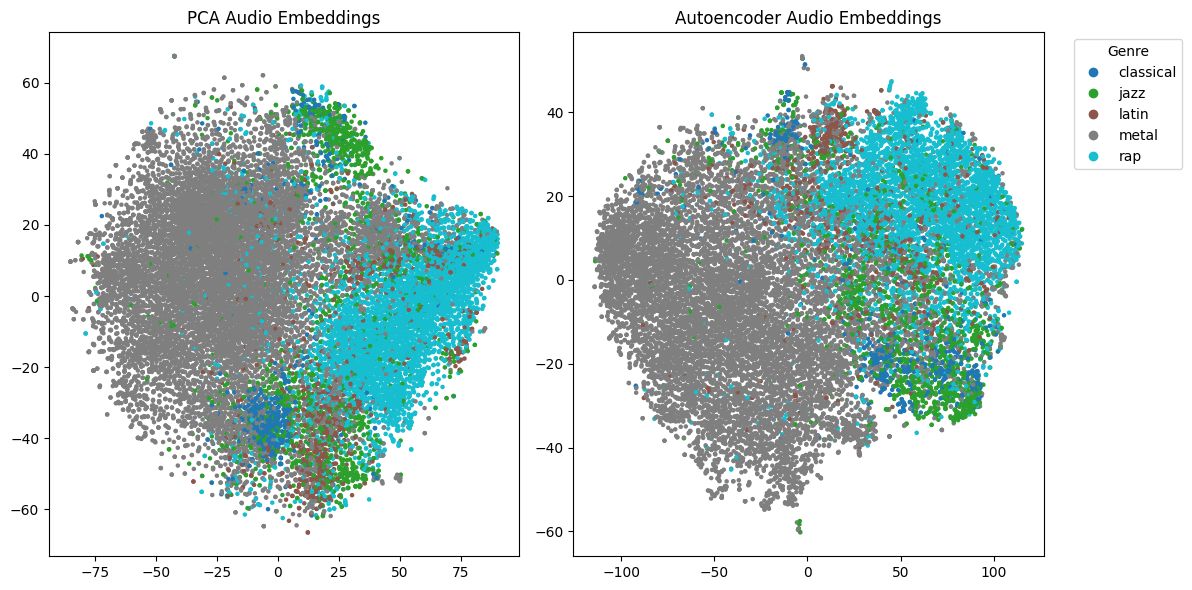

In [23]:
# --- Comparing the PCA and autoencoder embeddings with t-SNE visualization ---
scatter_plot_comparison(pca_audio_embeddings, autoenc_audio_embeddings, title1="PCA Audio Embeddings", title2="Autoencoder Audio Embeddings")

From the visualization of the audio embeddings (both PCA and Autoencoder-based), we can deduct that there is some patterns between the different genres. As we can see **metal** and **rap** have seemingly form distinctive clusters, while **latin** and **classical** music present also a similar pattern but less obvious. **Jazz** music is overlapping with latin and classical music showing that it has some resemblence with both.
In the next part, we will introduce classifiers to better capture the underlying structure of the data and improve genre discrimination.

**Comparison between Audio and Text Embeddings**

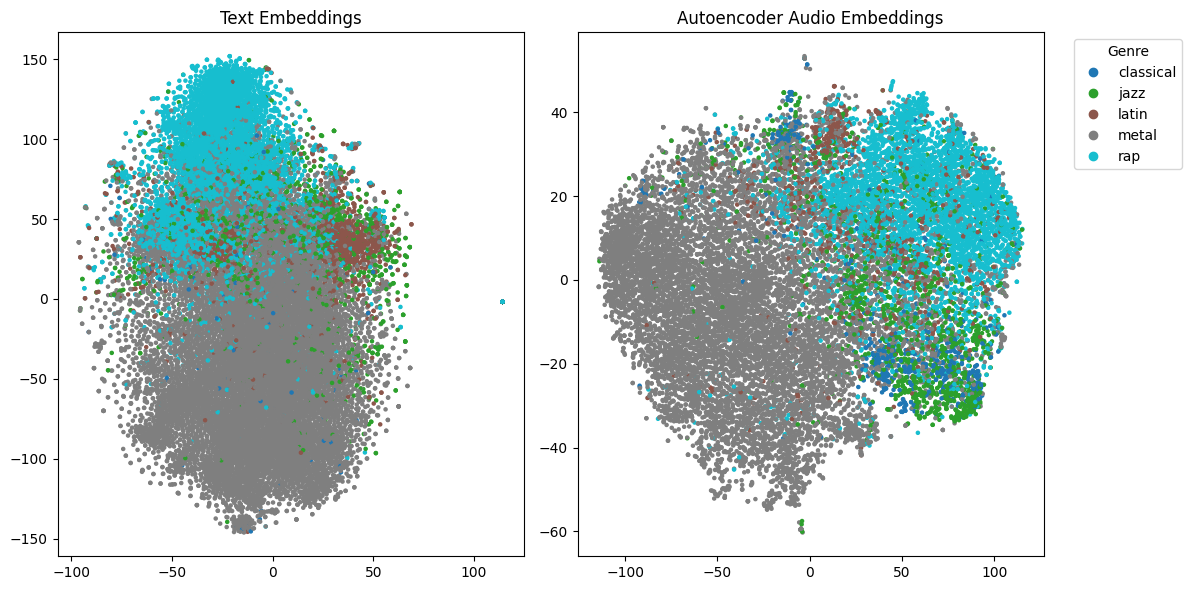

In [24]:
scatter_plot_comparison(embed1=text_embeddings_matrix, embed2=autoenc_audio_embeddings, title1="Text Embeddings", title2="Autoencoder Audio Embeddings")

The visualisation of text embeddings gives us also useful insight as far as the genres of the songs are concerned. It shows an even more strong cluster for **rap** music, a normal consequence as rap is based a lot on the lyrics and also shows a better clustering for  **latin**. The other 3 genres(**jazz**, **metal** and **classical**) shows similar pattern in the text and audio embeddings, a fact that reveals that they do not have a big difference between the uniqueness of their lyrics and their audio.

### **Cosine Similarity**

In [25]:
from sklearn.metrics.pairwise import cosine_similarity

similarity_matrix_autoenc = cosine_similarity(autoenc_audio_embeddings)
similarity_matrix_pca = cosine_similarity(pca_audio_embeddings)
similarity_matrix_text = cosine_similarity(text_embeddings_matrix)

def top_n_similar_songs(song_pos, data, similarity_matrix=similarity_matrix_autoenc, n=5):
    
    similarity_df = pd.DataFrame(similarity_matrix, index=data['id'], columns=data['id'])
    song_id = data['id'].iloc[song_pos]      
    
    similar_songs = similarity_df.loc[song_id].sort_values(ascending=False)[1:n+1]
    similar_songs_ids = similar_songs.index.tolist()
    similar_songs_names = data[data['id'].isin(similar_songs_ids)][["song","genres","main_genre"]]
    
    return similar_songs_names



**Cosine similarity: PCA vs Autoencoder**  


In [27]:
# --- Example: top 5 similar songs to i-th song in the dataset using audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_autoenc, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_pca, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

Top 5 similar songs to the Sign of the Times' (Autoencoder):
                           song  \
2293               Burn With Me   
2490   Communion and the Oracle   
7502            Veil of Elysium   
14767          Wings of Destiny   
17073                The Burden   

                                                  genres main_genre  
2293             [metal, power metal, alternative metal]      metal  
2490             [progressive metal, metal, power metal]      metal  
7502   [progressive metal, symphonic metal, symphonic...      metal  
14767        [metal, symphonic power metal, power metal]      metal  
17073                                  [nu metal, metal]      metal  
Top 5 similar songs to the Sign of the Times' (PCA):
                     song                                             genres  \
462         Original Face  [sludge metal, stoner metal, doom metal, post-...   
4977     One Last Goodbye  [progressive metal, doom metal, progressive rock]   
7502      Veil 


After experimenting on the cosine similarity of the songs and extracting the top-5 similar songs of a variety of songs using the PCA embeddings and the autoencoder embeddings, we notice that similarity results differ between PCA-based and Autoencoder-based embeddings, indicating that each method captures different aspects of the audio data.  
PCA is a linear dimensionality reduction technique that is based on the variance. As a result, it tends to capture more global and general characteristics of the songs and brings close songs with similar high-level structure.  
The Autoencoder, as a non-linear model, learns more complex similarity patterns between the songs and possibly can capture more deep relationships between the MFCC stats.  
Different embedding methods emphasize different properties of the data, leading to different nearest-neighbor relationships between songs.


**Cosine Similarity: Audio Embeddings vs Text Embeddings**

In [29]:
# --- Top 5 similar songs: Comparison between text and audio embeddings ---
song_position = 1
top_5_similar_songs_enc = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_autoenc, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Autoencoder):")
print(top_5_similar_songs_enc)

top_5_similar_songs_pca = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_pca, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (PCA):")
print(top_5_similar_songs_pca)

top_n_similar_songs_text = top_n_similar_songs(song_pos=song_position, data=data, similarity_matrix=similarity_matrix_text, n=5)
print("Top 5 similar songs to the " + data['song'].iloc[song_position] + "' (Text):")
print(top_n_similar_songs_text)

Top 5 similar songs to the Sign of the Times' (Autoencoder):
                           song  \
2293               Burn With Me   
2490   Communion and the Oracle   
7502            Veil of Elysium   
14767          Wings of Destiny   
17073                The Burden   

                                                  genres main_genre  
2293             [metal, power metal, alternative metal]      metal  
2490             [progressive metal, metal, power metal]      metal  
7502   [progressive metal, symphonic metal, symphonic...      metal  
14767        [metal, symphonic power metal, power metal]      metal  
17073                                  [nu metal, metal]      metal  
Top 5 similar songs to the Sign of the Times' (PCA):
                     song                                             genres  \
462         Original Face  [sludge metal, stoner metal, doom metal, post-...   
4977     One Last Goodbye  [progressive metal, doom metal, progressive rock]   
7502      Veil 

***Comparison of the different Embeddings***

We present a small comparison between the different embeddings to reveal which one "groups" together better songs of the same genre. Our metric is the average recall for the each type of embeddings, that shows at which percentage the k-Nearest Neighbors of a query songs belong to the same category as the query.  
The metric is not absolute and we do not compare with a ground truth, we just make an observation about the "clustering" of the songs. We realise that a song can be similar with a song of different category but in general we assume that similar songs are more probable (therefore "correct") to belong to the same category.

In [30]:
'''
Function to calculate the recall@n of the nearest neighbors
that actually belong to the same 'genre' like the query.

Purpose of the function is to analyse which embeddings( Audio(PCA and Autoencoder) or Text )
are bringing "closer" data of the same genre.
'''
def recall_of_same_genre(data, indices, similarity_matrix, n=10):
    total_recall = 0

    for i in indices:
        song_genre = data["main_genre"].iloc[i]

        similarities = similarity_matrix[i].copy()
        similarities[i] = -1
        top_indices = np.argsort(similarities)[-n:][::-1]

        top_genres = data.iloc[top_indices]["main_genre"].to_list()
        same = sum(genre == song_genre for genre in top_genres)

        total_recall += same / n

    return total_recall / len(indices)


In [32]:
embed_types = ["Autoencoder", "PCA", "TEXT"]

# pick random indices
np.random.seed(42)
random_indices = np.random.choice(len(data), size=2000, replace=False)
results = [
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_autoenc),
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_pca),
    recall_of_same_genre(data, random_indices, similarity_matrix=similarity_matrix_text),
    ]

header = " | ".join([f"{name:^15}" for name in embed_types])
separator = "-"*len(header)
values = " | ".join([f"{val:^15.4f}" for val in results])

print(separator)
print(header)
print(separator)
print(values)
print(separator)

---------------------------------------------------
  Autoencoder   |       PCA       |      TEXT      
---------------------------------------------------
    0.7548      |     0.7840      |     0.7053     
---------------------------------------------------
